# MOT 2024: can we predict an initial fail?

Step 7 of `docs/instructions.md`. **Target:** `is_initial_fail` (F or PRS on an initial Class 4 test). **Features:** vehicle age, mileage, make, fuel type and engine size, which is everything the results table knows about the car before the test.

The question isn't only "how accurate is it?" but also "how much of an MOT result is explained by these basic facts about the car, and how much depends on things the data doesn't record?"

In [1]:
import duckdb
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, SplineTransformer, StandardScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

con = duckdb.connect("../data/mot.duckdb", read_only=True)

## 1. Sample and split by vehicle

The full scope has 33 million tests, but a 5% sample of vehicles (about 1.6 million tests) is plenty for five features and keeps training to a few minutes.

**The split is by vehicle, not by test.** A car can have several initial tests in 2024 (for example, after a failed retest window). If the same car were in both training and test sets, the model could partly memorise it. `hash(vehicle_id) % 100` gives each vehicle a fixed bucket. Buckets 0–4 are the 5% sample. Within them, bucket 4 (`bucket % 5 == 4`) is for testing and buckets 0–3 are for training. On the small `data/sample` build, all vehicles are used with the same one-in-five test split.

The 40 most-tested makes keep their own category, and the rest are grouped as `OTHER`. Fuel types other than petrol, diesel, hybrid and electric are grouped as `Other`.

In [2]:
n_scope = con.sql("SELECT COUNT(*) FROM analysis_scope").fetchall()[0][0]
SAMPLE_PCT = 5 if n_scope > 1_000_000 else 100  # the small data/sample build is used whole

df = con.sql(f"""
    WITH top_makes AS (
        SELECT make FROM analysis_scope
        WHERE NOT is_unclassified
        GROUP BY make ORDER BY COUNT(*) DESC LIMIT 40
    )
    SELECT is_initial_fail::INT                                       AS failed,
           age,
           test_mileage                                               AS mileage,
           cylinder_capacity                                          AS engine_cc,
           CASE WHEN make IN (SELECT make FROM top_makes) THEN make ELSE 'OTHER' END AS make,
           CASE WHEN fuel_type IN ('PE', 'DI', 'HY', 'EL') THEN fuel_type_desc ELSE 'Other' END AS fuel,
           hash(vehicle_id) % 100                                     AS bucket
    FROM analysis_scope
    WHERE hash(vehicle_id) % 100 < {SAMPLE_PCT}
    ORDER BY test_id  -- fixed row order, so early stopping holds out the same rows every run
""").df()

features = ["age", "mileage", "engine_cc", "make", "fuel"]
for c in ["make", "fuel"]:
    df[c] = df[c].astype("category")

train, test = df[df["bucket"] % 5 < 4], df[df["bucket"] % 5 == 4]
X_train, y_train = train[features], train["failed"]
X_test, y_test = test[features], test["failed"]
print(f"train {len(train):,} tests, test {len(test):,} tests")
print(f"fail rate: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
df[features].isna().mean().round(4).rename("share missing")

train 1,318,304 tests, test 330,022 tests
fail rate: train 0.283, test 0.282


age          0.0001
mileage      0.0021
engine_cc    0.0136
make         0.0000
fuel         0.0000
Name: share missing, dtype: float64

## 2. Metrics

- **ROC AUC:** how well the model ranks a failing car above a passing one. 0.5 is a coin toss and 1.0 is perfect.
- **Log loss** and **Brier score:** how good the predicted *probabilities* are. Lower is better. They are what matters if the output is used as a "chance of failing".
- **Skill vs baseline:** the percentage reduction in Brier score compared with always predicting the average fail rate.

In [3]:
results = {}

def evaluate(name, p):
    results[name] = {
        "ROC AUC": roc_auc_score(y_test, p),
        "log loss": log_loss(y_test, p),
        "Brier": brier_score_loss(y_test, p),
    }
    return pd.DataFrame(results).T.round(4)

## 3. Baseline: predict the average fail rate for every car

In [4]:
p_base = np.full(len(y_test), y_train.mean())
evaluate("baseline", p_base)

,ROC AUC,log loss,Brier
baseline,0.5,0.5953,0.2027


## 4. Logistic regression

Logistic regression is linear, but the age effect is a hump (see `04_analysis.ipynb`: it rises to 18 years, then falls). So age and mileage go through **splines**, which let the model bend the curve. Missing values are filled with the median, plus a "was missing" flag so the model can learn whether missingness itself matters. Engine size is log-scaled.

In [5]:
spline = lambda: make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                               SplineTransformer(n_knots=8, degree=3))
logit = make_pipeline(
    ColumnTransformer([
        ("age", spline(), ["age"]),
        ("mileage", spline(), ["mileage"]),
        ("engine", make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                                 FunctionTransformer(np.log1p), StandardScaler()), ["engine_cc"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), ["make", "fuel"]),
    ]),
    LogisticRegression(max_iter=2000),
)
start = time.time()
logit.fit(X_train, y_train)
print(f"trained in {time.time() - start:.0f}s")
p_logit = logit.predict_proba(X_test)[:, 1]
evaluate("logistic regression", p_logit)

trained in 3s


,ROC AUC,log loss,Brier
baseline,0.5000,0.5953,0.2027
logistic regression,0.6874,0.5511,0.1853


## 5. Gradient-boosted trees

Tree models capture interactions without being told, for example that diesel cars wear differently with mileage than petrol cars do. `HistGradientBoostingClassifier` handles missing values and categorical columns natively. 10% of the training set is held out for early stopping, so the number of trees is chosen on unseen data.

In [6]:
hgb = HistGradientBoostingClassifier(
    categorical_features="from_dtype",
    max_iter=500, learning_rate=0.1, max_leaf_nodes=63,
    early_stopping=True, validation_fraction=0.1, random_state=42,
)
start = time.time()
hgb.fit(X_train, y_train)
print(f"trained in {time.time() - start:.0f}s, {hgb.n_iter_} trees")
p_hgb = hgb.predict_proba(X_test)[:, 1]
scores = evaluate("gradient boosting", p_hgb)
scores["Brier skill vs baseline (%)"] = (100 * (1 - scores["Brier"] / scores.loc["baseline", "Brier"])).round(1)
scores

trained in 3s, 89 trees


,ROC AUC,log loss,Brier,Brier skill vs baseline (%)
baseline,0.5000,0.5953,0.2027,0.0
logistic regression,0.6874,0.5511,0.1853,8.6
gradient boosting,0.6918,0.5484,0.1844,9.0


Both models clearly beat the baseline, but only modestly. **Gradient boosting reaches a ROC AUC of 0.692**: given one car that failed and one that passed, it ranks the failing car as riskier 69% of the time. Its probabilities are **9.0% better than guessing the average** (Brier score). The logistic regression with splines gets almost all of the way there (AUC 0.687), so the relationships are mostly smooth, separate effects of each feature, with little interaction for the trees to find.

## 6. Are the probabilities trustworthy? (calibration)

I sort the test cars into 10 equal groups by predicted probability and compare each group's average prediction with its actual fail rate. If the model is well calibrated, the points sit on the diagonal.

In [7]:
calib = (pd.DataFrame({"pred": p_hgb, "actual": y_test.to_numpy()})
           .assign(decile=lambda d: pd.qcut(d["pred"], 10, labels=False) + 1)
           .groupby("decile").agg(predicted=("pred", "mean"), actual=("actual", "mean"), tests=("pred", "size")))
calib.round(3)

,predicted,actual,tests
decile,,,
1,0.091,0.087,33003
2,0.133,0.133,33003
3,0.168,0.165,33001
4,0.203,0.201,33008
5,0.244,0.244,32996
6,0.292,0.297,33003
7,0.344,0.338,33008
8,0.395,0.393,32995
9,0.450,0.450,33006


The model is **very well calibrated**: in every decile, the average prediction is within 0.6 percentage points of the actual fail rate. But its predictions only range from about 9% to 52%. It can sort cars into risk groups (the riskiest tenth fails 51.6% of the time, six times the safest tenth's 8.7%), but it can never say confidently that a particular car *will* fail.

## 7. Which features matter? (permutation importance)

Shuffle one feature at a time on 50,000 test cars and measure how much the ROC AUC drops. The bigger the drop, the more the model relies on that feature. This is measured on the test set, so it reflects what the model generalises, not what it memorised.

In [8]:
sub = X_test.sample(min(50_000, len(X_test)), random_state=0)
imp = permutation_importance(hgb, sub, y_test.loc[sub.index], scoring="roc_auc",
                             n_repeats=3, random_state=0, n_jobs=-1)
importance = (pd.DataFrame({"feature": features, "AUC drop": imp.importances_mean, "sd": imp.importances_std})
                .sort_values("AUC drop", ascending=False).round(4))
importance

,feature,AUC drop,sd
1,mileage,0.0749,0.0007
0,age,0.0529,0.0013
3,make,0.0221,0.0002
2,engine_cc,0.0140,0.0005
4,fuel,0.0021,0.0003


**Mileage is the most important feature** (AUC drop 0.075), followed by **age** (0.053), then make (0.022) and engine size (0.014). **Fuel type adds almost nothing** (0.002) once the others are known. The fuel differences in `04_analysis.ipynb` are probably largely explained by mileage, because diesels are typically bought for high-mileage driving. Note that age and mileage are correlated, so part of their shared effect is credited to whichever one is left unshuffled, and both numbers understate their combined importance.

## 8. What the model says about example cars

Predicted chance of an initial fail for a few typical profiles.

In [9]:
profiles = pd.DataFrame([
    {"car": "3-year-old Toyota hybrid, 25k miles",  "age": 3,  "mileage": 25_000,  "engine_cc": 1798, "make": "TOYOTA",  "fuel": "Hybrid"},
    {"car": "3-year-old Tesla, 30k miles",          "age": 3,  "mileage": 30_000,  "engine_cc": np.nan, "make": "TESLA", "fuel": "Electric"},
    {"car": "8-year-old Ford Fiesta petrol, 60k",   "age": 8,  "mileage": 60_000,  "engine_cc": 998,  "make": "FORD",    "fuel": "Petrol"},
    {"car": "10-year-old Volkswagen diesel, 100k",  "age": 10, "mileage": 100_000, "engine_cc": 1968, "make": "VOLKSWAGEN", "fuel": "Diesel"},
    {"car": "12-year-old Renault diesel, 110k",     "age": 12, "mileage": 110_000, "engine_cc": 1461, "make": "RENAULT", "fuel": "Diesel"},
    {"car": "12-year-old Honda petrol, 80k",        "age": 12, "mileage": 80_000,  "engine_cc": 1339, "make": "HONDA",   "fuel": "Petrol"},
])
X_prof = profiles[features].astype({"make": df["make"].dtype, "fuel": df["fuel"].dtype})
profiles["chance of failing"] = (100 * hgb.predict_proba(X_prof)[:, 1]).round(0).astype(int).astype(str) + "%"
profiles[["car", "chance of failing"]]

,car,chance of failing
0,"3-year-old Toyota hybrid, 25k miles",11%
1,"3-year-old Tesla, 30k miles",17%
2,"8-year-old Ford Fiesta petrol, 60k",34%
3,"10-year-old Volkswagen diesel, 100k",26%
4,"12-year-old Renault diesel, 110k",54%
5,"12-year-old Honda petrol, 80k",31%


The examples reflect the analysis. A 12-year-old Renault diesel with 110k miles has a **54%** chance of failing, against **31%** for a 12-year-old Honda petrol with 80k. A 3-year-old Tesla (17%) is predicted to fail more often than a 3-year-old Toyota hybrid (11%), consistent with the tyre wear on electric cars.

## 9. Charts

In [10]:
SLOT = ["#2a78d6", "#eb6834"]
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False,
})
import textwrap
def finish(fig, ax, name, source="DVSA anonymised MOT tests 2024, Class 4 initial tests, held-out vehicles"):
    width = int(fig.get_figwidth() * 6.5)  # characters per title line that fit this figure
    ax.set_title(textwrap.fill(ax.get_title(loc="left"), width), loc="left")
    fig.text(0.01, 0.01, source, fontsize=9, color=INK_2)
    fig.tight_layout(rect=(0, 0.04, 1, 1))
    fig.savefig(f"../reports/figures/{name}.png", dpi=150)
    plt.show()

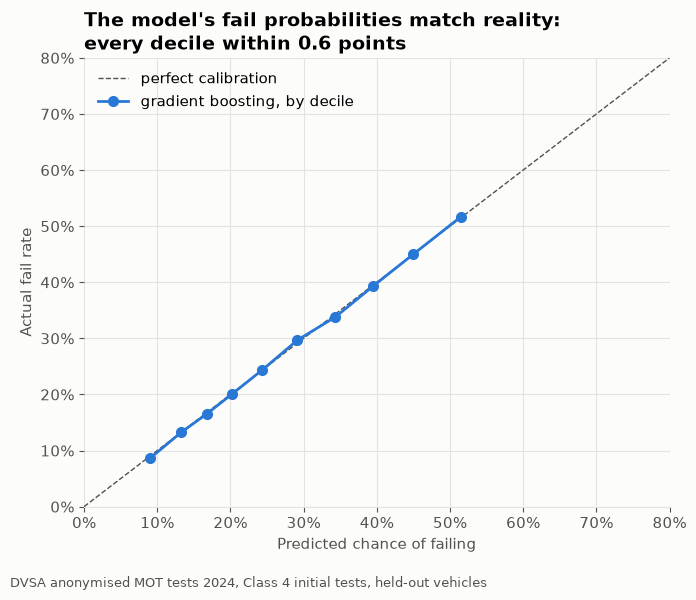

In [11]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 0.8], [0, 0.8], color=INK_2, linewidth=1, linestyle="--", label="perfect calibration")
ax.plot(calib["predicted"], calib["actual"], color=SLOT[0], marker="o", markersize=7, label="gradient boosting, by decile")
ax.set_title("The model's fail probabilities match reality: every decile within 0.6 points")
ax.set_xlabel("Predicted chance of failing"); ax.set_ylabel("Actual fail rate")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlim(0, 0.8); ax.set_ylim(0, 0.8); ax.legend(loc="upper left")
finish(fig, ax, "07_model_calibration")

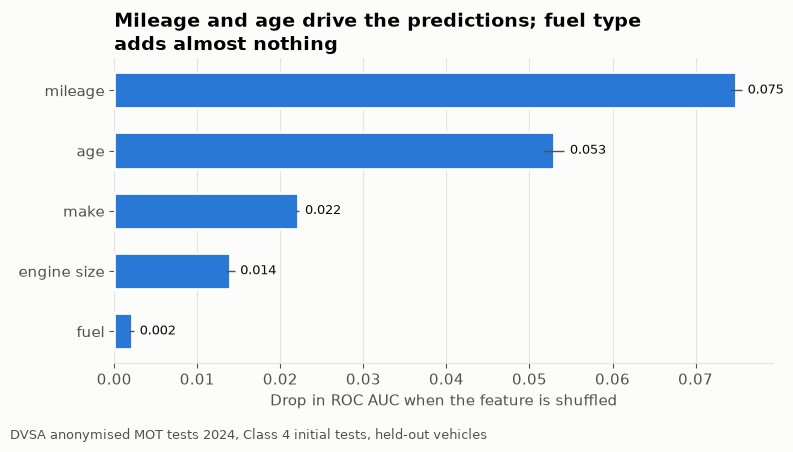

In [12]:
d = importance.sort_values("AUC drop")
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.barh(d["feature"].replace({"engine_cc": "engine size"}), d["AUC drop"], xerr=d["sd"], color=SLOT[0], height=0.6,
               edgecolor=SURFACE, linewidth=2, error_kw={"ecolor": INK_2, "lw": 1})
ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=9, color=INK)
ax.set_title("Mileage and age drive the predictions; fuel type adds almost nothing")
ax.set_xlabel("Drop in ROC AUC when the feature is shuffled"); ax.grid(axis="y", visible=False)
finish(fig, ax, "08_feature_importance")

## 10. Conclusions and limitations

**What the model shows**

- The basic facts about a car (age, mileage, make, engine size and fuel) explain a real but limited part of the MOT result: an AUC of 0.69, and probabilities 9% better than guessing the average.
- That's useful for **risk groups** (a six-fold spread between the riskiest and safest tenths, with trustworthy probabilities), not for predicting an individual car.
- **Mileage and age dominate.** Make adds a little, and fuel type almost nothing once the rest is known.
- A simple, explainable logistic regression performs almost as well as gradient boosting, so I'd use it in practice.

**Limitations**

- **What the data doesn't record decides most outcomes:** service history, how and where the car is driven, whether the owner fixes things before the test, and differences between testers and garages.
- **The strongest missing predictor is probably the car's own history.** The data has a `vehicle_id`, so adding 2023 results would let a model use last year's result and advisories (if a car got an advisory for worn tyres last year, it's more likely to fail on tyres this year). That's the natural next step.
- Trained on a 5% sample of vehicles from one year. Makes outside the top 40 are grouped as `OTHER`.
- Conflicting tests (0.4%) were excluded during cleaning, and their bias check only covered the overall rate.

In [13]:
con.close()